# Water Quality Analysis Across States and Identification of Pollution Hotspots

## Problem Statement: PS-65

## Project ID: PS-65

**Student Name:** Paidi Karthik
**Roll No:** 160125737028 **Department:** Information Technology
**Institution:** Chaitanya Bharathi Institute of Technology, Hyderabad

---

## Problem Overview

Water quality varies across different states, rivers, and sampling locations. This project analyzes important water quality parameters to understand pollution patterns and identify potential pollution hotspots.

The analysis focuses on parameters such as:

- Temperature
- Dissolved Oxygen (DO)
- pH
- Conductivity
- Biochemical Oxygen Demand (BOD)
- Nitrate and Nitrite
- Fecal Coliform
- Total Coliform

The project involves data loading, data cleaning, exploratory data analysis, statistical analysis, missing-value treatment, visualization, and multi-parameter hotspot identification.

## Dataset

The dataset is obtained from the Government of India's Data.gov.in water-quality monitoring resources.

**Dataset:** Water Quality in India - 2013

**Source:** [Data.gov.in](https://data.gov.in)

The collected data consists of multiple CSV files containing water-quality measurements from different monitoring locations.

## Environment and Libraries

This project is implemented using Python in Jupyter Notebook.

### Libraries

- **Pandas** – data loading, cleaning, filtering and grouping
- **NumPy** – numerical operations
- **Matplotlib** – data visualization
- **Seaborn** – statistical visualization
- **Scikit-learn** – advanced analysis such as clustering or PCA, if required

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.15.0 (tags/v3.15.0:d220409, Oct  9 2026, 11:55:56) [MSC v.1951 64 bit (AMD64)]


In [3]:
from pathlib import Path

raw_data_path = Path("raw_data")
if not raw_data_path.exists():
    raw_data_path = Path("WaterQualityHotspot") / "raw_data"
if not raw_data_path.exists():
    raise FileNotFoundError(f"Could not find the raw_data folder from {Path.cwd()}")

csv_files = sorted(raw_data_path.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {raw_data_path.resolve()}")

print("Number of CSV files found:", len(csv_files))

Number of CSV files found: 36


In [4]:
# Read the first CSV file
df_test = pd.read_csv(csv_files[0], encoding="cp1252")

print("File loaded successfully!")
print("File name:", csv_files[0].name)
print("Shape:", df_test.shape)

File loaded successfully!
File name: water_quality_of_medium_minor_rivers_goa-2013.csv
Shape: (28, 27)


In [5]:
df_test.head()

,STATION CODE,LOCATIONS,STATE,TEMPERATURE ºC : Min,TEMPERATURE ºC : Max,TEMPERATURE ºC : Mean,D.O. (mg/l) : Min : > 4 mg/l,D.O. (mg/l) : Max : > 4 mg/l,D.O. (mg/l) : Mean : > 4 mg/l,pH : Min : 6.5-8.5,...,B.O.D. (mg/l) : Mean : < 3 mg/l,NITRATE- N+ NITRITE-N (mg/l) : Min,NITRATE- N+ NITRITE-N (mg/l) : Max,NITRATE- N+ NITRITE-N (mg/l) : Mean,FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml
0,1399,ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...,GOA,27,32,30.0,4.7,7.6,5.6,6.8,...,2.0,0.08,0.08,0.08,130,22000,7022,230,35000,13410
1,1475,ZUARI AT PANCHAWADI,GOA,28,33,30.4,3.5,7.3,5.5,5.9,...,0.8,0.02,0.69,0.17,180,7900,1893,180,13000,2915
2,3181,RIVER ZUARI AT BORIM BRIDGE,GOA,27,34,30.8,3.8,7.0,5.5,5.8,...,1.5,0.01,0.19,0.09,200,13000,3293,450,24000,6264
3,3182,RIVER ZUARI AT MARCAIM JETTY,GOA,27,34,30.3,3.7,6.8,5.3,6.5,...,1.5,0.03,0.13,0.08,200,7900,1976,200,13000,3080
4,1400,"MANDOVI AT NEGHBOURHOOD OF PANAJI, GOA",GOA,27,33,30.1,4.9,7.1,6.0,6.6,...,1.2,0.03,0.56,0.17,200,13000,5129,180,24000,6086


In [6]:
for i, column in enumerate(df_test.columns):
    print(i, "->", column)

0 -> STATION CODE
1 -> LOCATIONS
2 -> STATE
3 -> TEMPERATURE ºC  : Min
4 -> TEMPERATURE ºC  : Max
5 -> TEMPERATURE ºC  : Mean
6 -> D.O. (mg/l)  : Min  : > 4 mg/l
7 -> D.O. (mg/l)  : Max  : > 4 mg/l
8 -> D.O. (mg/l)  : Mean  : > 4 mg/l
9 -> pH  : Min  : 6.5-8.5
10 -> pH  : Max  : 6.5-8.5
11 -> pH  : Mean  : 6.5-8.5
12 -> CONDUCTIVITY (µmhos/cm)  : Min
13 -> CONDUCTIVITY (µmhos/cm)  : Max
14 -> CONDUCTIVITY (µmhos/cm)  : Mean
15 -> B.O.D. (mg/l)  : Min  : < 3 mg/l
16 -> B.O.D. (mg/l)  : Max  : < 3 mg/l
17 -> B.O.D. (mg/l)  : Mean  : < 3 mg/l
18 -> NITRATE- N+ NITRITE-N (mg/l)  : Min
19 -> NITRATE- N+ NITRITE-N (mg/l)  : Max
20 -> NITRATE- N+ NITRITE-N (mg/l)  : Mean
21 -> FECAL COLIFORM (MPN/100ml)  : Min  : < 2500 MPN/100ml
22 -> FECAL COLIFORM (MPN/100ml)  : Max  : < 2500 MPN/100ml
23 -> FECAL COLIFORM (MPN/100ml)  : Mean  : < 2500 MPN/100ml
24 -> TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml
25 -> TOTAL COLIFORM (MPN/100ml)  : Max  : < 5000 MPN/100ml
26 -> TOTAL COLIFORM (MPN/

In [7]:
# Check the data types of all columns
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 27 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   STATION CODE                                            28 non-null     int64  
 1   LOCATIONS                                               28 non-null     str    
 2   STATE                                                   28 non-null     str    
 3   TEMPERATURE ºC  : Min                                   28 non-null     int64  
 4   TEMPERATURE ºC  : Max                                   28 non-null     int64  
 5   TEMPERATURE ºC  : Mean                                  28 non-null     float64
 6   D.O. (mg/l)  : Min  : > 4 mg/l                          28 non-null     float64
 7   D.O. (mg/l)  : Max  : > 4 mg/l                          28 non-null     float64
 8   D.O. (mg/l)  : Mean  : > 4 mg/l                      

In [8]:
# Count missing values in each column
missing_values = df_test.isnull().sum()

print(missing_values)

STATION CODE                                              0
LOCATIONS                                                 0
STATE                                                     0
TEMPERATURE ºC  : Min                                     0
TEMPERATURE ºC  : Max                                     0
TEMPERATURE ºC  : Mean                                    0
D.O. (mg/l)  : Min  : > 4 mg/l                            0
D.O. (mg/l)  : Max  : > 4 mg/l                            0
D.O. (mg/l)  : Mean  : > 4 mg/l                           0
pH  : Min  : 6.5-8.5                                      0
pH  : Max  : 6.5-8.5                                      0
pH  : Mean  : 6.5-8.5                                     0
CONDUCTIVITY (µmhos/cm)  : Min                            0
CONDUCTIVITY (µmhos/cm)  : Max                            0
CONDUCTIVITY (µmhos/cm)  : Mean                           0
B.O.D. (mg/l)  : Min  : < 3 mg/l                          0
B.O.D. (mg/l)  : Max  : < 3 mg/l        

In [9]:
# Create an empty list to store each CSV DataFrame
all_data = []

# Read every CSV file
for file in csv_files:
    df = pd.read_csv(file, encoding="cp1252")

    # Store the source file name
    df["SOURCE_FILE"] = file.name

    # Add the DataFrame to our list
    all_data.append(df)

print("Files loaded:", len(all_data))

Files loaded: 36


In [10]:
# Combine all 36 DataFrames into one master DataFrame
master_df = pd.concat(all_data, ignore_index=True)

print("Master dataset created!")
print("Rows:", master_df.shape[0])
print("Columns:", master_df.shape[1])

Master dataset created!
Rows: 947
Columns: 28


In [11]:
print("Dataset shape:", master_df.shape)

print("\nFirst 5 rows:")
display(master_df.head())

print("\nColumn names:")
print(master_df.columns.tolist())

Dataset shape: (947, 28)

First 5 rows:


,STATION CODE,LOCATIONS,STATE,TEMPERATURE ºC : Min,TEMPERATURE ºC : Max,TEMPERATURE ºC : Mean,D.O. (mg/l) : Min : > 4 mg/l,D.O. (mg/l) : Max : > 4 mg/l,D.O. (mg/l) : Mean : > 4 mg/l,pH : Min : 6.5-8.5,...,NITRATE- N+ NITRITE-N (mg/l) : Min,NITRATE- N+ NITRITE-N (mg/l) : Max,NITRATE- N+ NITRITE-N (mg/l) : Mean,FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml,SOURCE_FILE
0,1399,ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...,GOA,27.0,32.0,30.0,4.7,7.6,5.6,6.8,...,0.08,0.08,0.08,130.0,22000.0,7022.0,230,35000.0,13410.0,water_quality_of_medium_minor_rivers_goa-2013.csv
1,1475,ZUARI AT PANCHAWADI,GOA,28.0,33.0,30.4,3.5,7.3,5.5,5.9,...,0.02,0.69,0.17,180.0,7900.0,1893.0,180,13000.0,2915.0,water_quality_of_medium_minor_rivers_goa-2013.csv
2,3181,RIVER ZUARI AT BORIM BRIDGE,GOA,27.0,34.0,30.8,3.8,7.0,5.5,5.8,...,0.01,0.19,0.09,200.0,13000.0,3293.0,450,24000.0,6264.0,water_quality_of_medium_minor_rivers_goa-2013.csv
3,3182,RIVER ZUARI AT MARCAIM JETTY,GOA,27.0,34.0,30.3,3.7,6.8,5.3,6.5,...,0.03,0.13,0.08,200.0,7900.0,1976.0,200,13000.0,3080.0,water_quality_of_medium_minor_rivers_goa-2013.csv
4,1400,"MANDOVI AT NEGHBOURHOOD OF PANAJI, GOA",GOA,27.0,33.0,30.1,4.9,7.1,6.0,6.6,...,0.03,0.56,0.17,200.0,13000.0,5129.0,180,24000.0,6086.0,water_quality_of_medium_minor_rivers_goa-2013.csv



Column names:
['STATION CODE', 'LOCATIONS', 'STATE', 'TEMPERATURE ºC  : Min', 'TEMPERATURE ºC  : Max', 'TEMPERATURE ºC  : Mean', 'D.O. (mg/l)  : Min  : > 4 mg/l', 'D.O. (mg/l)  : Max  : > 4 mg/l', 'D.O. (mg/l)  : Mean  : > 4 mg/l', 'pH  : Min  : 6.5-8.5', 'pH  : Max  : 6.5-8.5', 'pH  : Mean  : 6.5-8.5', 'CONDUCTIVITY (µmhos/cm)  : Min', 'CONDUCTIVITY (µmhos/cm)  : Max', 'CONDUCTIVITY (µmhos/cm)  : Mean', 'B.O.D. (mg/l)  : Min  : < 3 mg/l', 'B.O.D. (mg/l)  : Max  : < 3 mg/l', 'B.O.D. (mg/l)  : Mean  : < 3 mg/l', 'NITRATE- N+ NITRITE-N (mg/l)  : Min', 'NITRATE- N+ NITRITE-N (mg/l)  : Max', 'NITRATE- N+ NITRITE-N (mg/l)  : Mean', 'FECAL COLIFORM (MPN/100ml)  : Min  : < 2500 MPN/100ml', 'FECAL COLIFORM (MPN/100ml)  : Max  : < 2500 MPN/100ml', 'FECAL COLIFORM (MPN/100ml)  : Mean  : < 2500 MPN/100ml', 'TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml', 'TOTAL COLIFORM (MPN/100ml)  : Max  : < 5000 MPN/100ml', 'TOTAL COLIFORM (MPN/100ml)  : Mean  : < 5000 MPN/100ml', 'SOURCE_FILE']


In [12]:
# Count missing values in every column
missing_values = master_df.isnull().sum()

# Show only columns that contain missing values
missing_values = missing_values[missing_values > 0]

print("Columns containing missing values:")
print(missing_values.sort_values(ascending=False))

Columns containing missing values:
FECAL COLIFORM (MPN/100ml)  : Mean  : < 2500 MPN/100ml    151
FECAL COLIFORM (MPN/100ml)  : Max  : < 2500 MPN/100ml     151
FECAL COLIFORM (MPN/100ml)  : Min  : < 2500 MPN/100ml     151
TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml      96
TOTAL COLIFORM (MPN/100ml)  : Max  : < 5000 MPN/100ml      96
TOTAL COLIFORM (MPN/100ml)  : Mean  : < 5000 MPN/100ml     96
TEMPERATURE ºC  : Min                                      41
TEMPERATURE ºC  : Max                                      41
TEMPERATURE ºC  : Mean                                     41
CONDUCTIVITY (µmhos/cm)  : Mean                            40
CONDUCTIVITY (µmhos/cm)  : Min                             40
CONDUCTIVITY (µmhos/cm)  : Max                             40
D.O. (mg/l)  : Min  : > 4 mg/l                             37
D.O. (mg/l)  : Max  : > 4 mg/l                             37
D.O. (mg/l)  : Mean  : > 4 mg/l                            37
B.O.D. (mg/l)  : Min  : < 3 mg/l   

In [13]:
# Calculate missing values in each column
missing_count = master_df.isnull().sum()

# Calculate the percentage of missing values
missing_percent = (missing_count / len(master_df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

# Show columns with missing values first
missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,151,15.95
FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,151,15.95
FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,151,15.95
TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,96,10.14
TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml,96,10.14
TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,96,10.14
TEMPERATURE ºC : Min,41,4.33
TEMPERATURE ºC : Max,41,4.33
TEMPERATURE ºC : Mean,41,4.33
CONDUCTIVITY (µmhos/cm) : Min,40,4.22


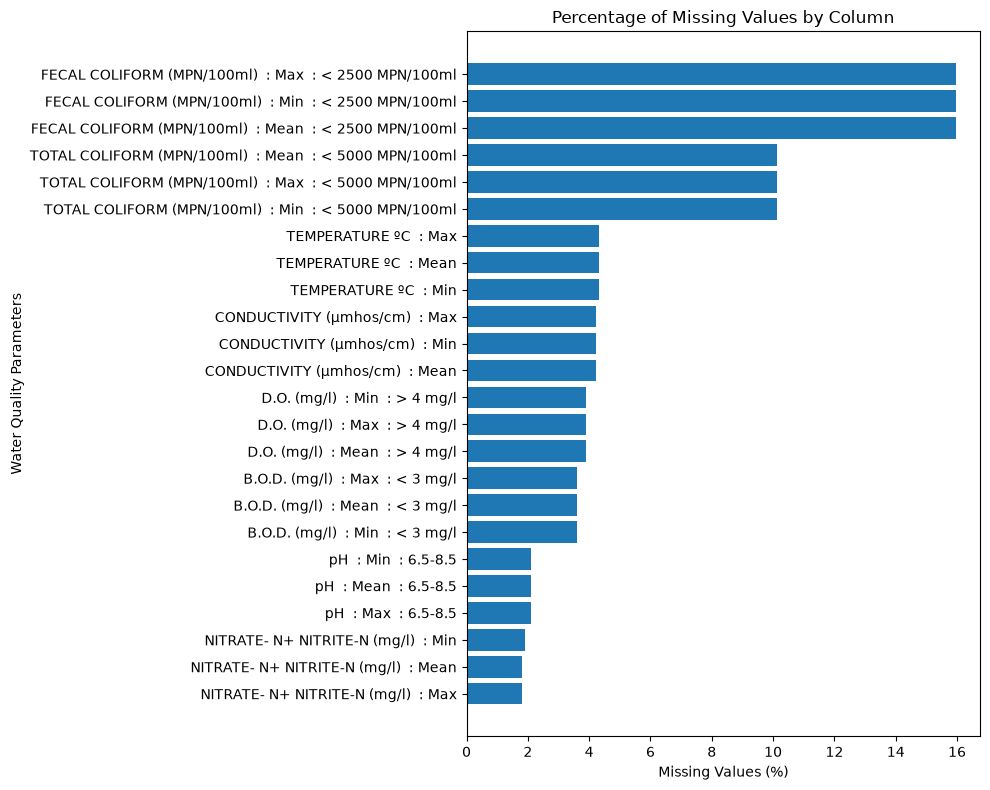

In [14]:
# Select columns that contain missing values
missing_plot = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Missing Percentage")

# Plot missing-value percentages
plt.figure(figsize=(10, 8))

plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Water Quality Parameters")
plt.tight_layout()
plt.show()

In [15]:
# Count rows where all three measurements are missing
parameters = [
    "FECAL COLIFORM (MPN/100ml)  : Min  : < 2500 MPN/100ml",
    "FECAL COLIFORM (MPN/100ml)  : Max  : < 2500 MPN/100ml",
    "FECAL COLIFORM (MPN/100ml)  : Mean  : < 2500 MPN/100ml"
]

print("Rows missing all three fecal coliform measurements:",
      master_df[parameters].isnull().all(axis=1).sum())

print("\nRows missing at least one fecal coliform measurement:",
      master_df[parameters].isnull().any(axis=1).sum())

Rows missing all three fecal coliform measurements: 151

Rows missing at least one fecal coliform measurement: 151


In [16]:
# Check missing values for each water-quality parameter
parameter_groups = {
    "Temperature": [
        "TEMPERATURE ºC  : Min",
        "TEMPERATURE ºC  : Max",
        "TEMPERATURE ºC  : Mean"
    ],
    "Dissolved Oxygen": [
        "D.O. (mg/l)  : Min  : > 4 mg/l",
        "D.O. (mg/l)  : Max  : > 4 mg/l",
        "D.O. (mg/l)  : Mean  : > 4 mg/l"
    ],
    "pH": [
        "pH  : Min  : 6.5-8.5",
        "pH  : Max  : 6.5-8.5",
        "pH  : Mean  : 6.5-8.5"
    ],
    "Fecal Coliform": [
        "FECAL COLIFORM (MPN/100ml)  : Min  : < 2500 MPN/100ml",
        "FECAL COLIFORM (MPN/100ml)  : Max  : < 2500 MPN/100ml",
        "FECAL COLIFORM (MPN/100ml)  : Mean  : < 2500 MPN/100ml"
    ]
}

for parameter, columns in parameter_groups.items():
    count = master_df[columns].isnull().all(axis=1).sum()
    print(f"{parameter}: {count} rows missing all three measurements")

Temperature: 41 rows missing all three measurements
Dissolved Oxygen: 37 rows missing all three measurements
pH: 20 rows missing all three measurements
Fecal Coliform: 151 rows missing all three measurements


In [17]:
parameter_groups.update({
    "Conductivity": [
        "CONDUCTIVITY (µmhos/cm)  : Min",
        "CONDUCTIVITY (µmhos/cm)  : Max",
        "CONDUCTIVITY (µmhos/cm)  : Mean"
    ],
    "BOD": [
        "B.O.D. (mg/l)  : Min  : < 3 mg/l",
        "B.O.D. (mg/l)  : Max  : < 3 mg/l",
        "B.O.D. (mg/l)  : Mean  : < 3 mg/l"
    ],
    "Nitrate/Nitrite": [
        "NITRATE- N+ NITRITE-N (mg/l)  : Min",
        "NITRATE- N+ NITRITE-N (mg/l)  : Max",
        "NITRATE- N+ NITRITE-N (mg/l)  : Mean"
    ],
    "Total Coliform": [
        "TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml",
        "TOTAL COLIFORM (MPN/100ml)  : Max  : < 5000 MPN/100ml",
        "TOTAL COLIFORM (MPN/100ml)  : Mean  : < 5000 MPN/100ml"
    ]
})

for parameter, columns in parameter_groups.items():
    count = master_df[columns].isnull().all(axis=1).sum()
    print(f"{parameter}: {count} rows missing all three measurements")

Temperature: 41 rows missing all three measurements
Dissolved Oxygen: 37 rows missing all three measurements
pH: 20 rows missing all three measurements
Fecal Coliform: 151 rows missing all three measurements
Conductivity: 40 rows missing all three measurements
BOD: 34 rows missing all three measurements
Nitrate/Nitrite: 17 rows missing all three measurements
Total Coliform: 96 rows missing all three measurements


In [18]:
# Create a separate copy for cleaning
clean_df = master_df.copy()

# Identify numerical columns
numeric_columns = clean_df.select_dtypes(
    include=np.number
).columns

# Fill missing numerical values using each column's median
for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

print("Original missing values:", master_df.isnull().sum().sum())
print("Missing values after imputation:", clean_df.isnull().sum().sum())

Original missing values: 1309
Missing values after imputation: 224


In [19]:
# Check missing values after imputation
print("Original dataset shape:", master_df.shape)
print("Cleaned dataset shape:", clean_df.shape)

print("\nMissing values before cleaning:",
      master_df.isnull().sum().sum())

print("Missing values after cleaning:",
      clean_df.isnull().sum().sum())

Original dataset shape: (947, 28)
Cleaned dataset shape: (947, 28)

Missing values before cleaning: 1309
Missing values after cleaning: 224


In [20]:
# Display remaining missing values
remaining_missing = clean_df.isnull().sum()
display(remaining_missing[remaining_missing > 0])

D.O. (mg/l)  : Min  : > 4 mg/l                           37
D.O. (mg/l)  : Max  : > 4 mg/l                           37
D.O. (mg/l)  : Mean  : > 4 mg/l                          37
NITRATE- N+ NITRITE-N (mg/l)  : Max                      17
TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml    96
dtype: int64

In [21]:
# Create a fresh copy of the original dataset
clean_df = master_df.copy()

# Convert measurement columns to numeric
for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    )

# Fill missing numerical values using the median
for column in numeric_columns:
    median_value = clean_df[column].median()

    if pd.notna(median_value):
        clean_df[column] = clean_df[column].fillna(median_value)

print("Missing values before cleaning:",
      master_df.isnull().sum().sum())

print("Missing values after cleaning:",
      clean_df.isnull().sum().sum())

Missing values before cleaning: 1309
Missing values after cleaning: 224


In [22]:
print("Original dataset shape:", master_df.shape)
print("Cleaned dataset shape:", clean_df.shape)

print("\nMissing values in original dataset:",
      master_df.isnull().sum().sum())

print("Missing values in cleaned dataset:",
      clean_df.isnull().sum().sum())

Original dataset shape: (947, 28)
Cleaned dataset shape: (947, 28)

Missing values in original dataset: 1309
Missing values in cleaned dataset: 224


In [23]:
remaining_missing = clean_df.isnull().sum()
display(remaining_missing[remaining_missing > 0])

D.O. (mg/l)  : Min  : > 4 mg/l                           37
D.O. (mg/l)  : Max  : > 4 mg/l                           37
D.O. (mg/l)  : Mean  : > 4 mg/l                          37
NITRATE- N+ NITRITE-N (mg/l)  : Max                      17
TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml    96
dtype: int64

## Question 1 (BL-3): Calculate Mean Pollutant Concentration

**Objective:** Calculate the average concentration of each water-quality parameter across all monitoring locations to understand the overall water-quality characteristics of the dataset.

In [24]:
# Select columns containing mean measurements
mean_columns = [
    column for column in clean_df.columns
    if ": Mean" in column
]

# Convert selected columns to numeric values
for column in mean_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    )

# Calculate mean for each parameter
mean_results = clean_df[mean_columns].mean()

print("Mean concentration of water-quality parameters:")
display(mean_results.to_frame(name="Mean Value"))

Mean concentration of water-quality parameters:


,Mean Value
TEMPERATURE ºC : Mean,24.718965
D.O. (mg/l) : Mean : > 4 mg/l,6.653201
pH : Mean : 6.5-8.5,7.702746
CONDUCTIVITY (µmhos/cm) : Mean,806.217529
B.O.D. (mg/l) : Mean : < 3 mg/l,4.731119
NITRATE- N+ NITRITE-N (mg/l) : Mean,1.928194
FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,164186.952482
TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml,203514.443506


### Interpretation of Results

The mean analysis shows variations across the water-quality parameters in the dataset. The average temperature is approximately 24.72 °C, the mean dissolved oxygen is 6.65 mg/L, and the average pH is 7.70. The mean BOD is 4.73 mg/L, while the combined nitrate/nitrite measurement averages 1.93 mg/L.

The fecal and total coliform measurements have high average values, indicating that these parameters require further investigation across individual monitoring locations. Overall means provide a general overview but may hide local pollution hotspots. Therefore, additional filtering, grouping, and visualization are required.

**Limitation:** Missing numerical values were treated using median imputation where possible. This may influence calculated means and must be considered when interpreting results.

## Question 2 (BL-3): Filter Data for Specific Pollutants

### Objective

To filter water-quality data based on a specific pollutant threshold and identify monitoring locations where the pollutant level exceeds the selected reference value.

### Description

In this analysis, the Biochemical Oxygen Demand (BOD) mean values are filtered using a threshold of 3 mg/L, based on the reference value indicated in the dataset's column heading. Locations with BOD mean values greater than 3 mg/L are selected for further investigation.

### Methodology

1. Identify the column containing mean BOD measurements.
2. Apply a condition to select rows where mean BOD exceeds 3 mg/L.
3. Display the station code, location, state, and corresponding BOD mean value.
4. Examine the filtered records to identify locations that may require further water-quality assessment.

### Expected Outcome

The analysis produces a subset of monitoring locations with mean BOD values above the selected threshold. These records can be investigated further alongside other water-quality parameters to understand potential pollution patterns.

**Note:** The 3 mg/L value is the reference shown in the dataset's column heading. Exceeding it is a screening criterion for this analysis, not by itself an official determination that a location is polluted.

In [25]:
# Identify the BOD mean column
bod_column = [
    column for column in clean_df.columns
    if "B.O.D." in column and ": Mean" in column
][0]

# Filter locations where BOD mean exceeds 3 mg/L
high_bod = clean_df[clean_df[bod_column] > 3]

print("Number of locations with BOD mean above 3 mg/L:",
      len(high_bod))

display(high_bod[["STATION CODE", "LOCATIONS", "STATE", bod_column]].head(10))

Number of locations with BOD mean above 3 mg/L: 329


,STATION CODE,LOCATIONS,STATE,B.O.D. (mg/l) : Mean : < 3 mg/l
21,3183,"RIVER SAL AT KHAREBAND, MARGAO",GOA,3.2
32,1434,AMLAKHADI AFTER CONFL. OF W. WATER FROM ANKLES...,GUJARAT,8.6
35,1436,BHADAR V/S JETPUR VILL. A/C OF W. WATER FROM J...,GUJARAT,103.8
41,1862,KAVERI ON BRIDGE AT BILLIMORA-VALSAD ROAD,GUJARAT,7.2
63,2443,GAUTAMI-GODAVARI RIVER,PONDICHERRY,4.0
64,2444,CORINGA RIVER,PONDICHERRY,5.0
65,2445,MAHE RIVER,PONDICHERRY,4.0
67,1159,TAMBIRAPARANI AT BDG.NR. MADURA COATS LTD.PAPA...,TAMILNADU,3.1
68,1160,"TAMBIRAPARANI AT CHERANMADEVI,CAUSE WAY,TAMILNADU",TAMILNADU,3.3
69,1161,"TAMBIRAPARANI AT TIRUNELVELI,COLLECTORATE,TAMI...",TAMILNADU,4.0


### Results and Interpretation

The filtering operation identified monitoring locations where the mean Biochemical Oxygen Demand (BOD) exceeded 3 mg/L. The displayed results include locations in Goa, Gujarat, Pondicherry, and Tamil Nadu.

Among the displayed records, Bhadar near Jetpur in Gujarat has a BOD mean of 103.8 mg/L, which is substantially higher than the selected reference value. Other locations, such as Amlakhadi in Gujarat and Coringa River in Pondicherry, also show elevated BOD measurements.

These results help identify locations that may require further investigation. However, the filtered values alone do not establish the overall pollution status of a water body; additional parameters and local environmental standards should also be considered.

## Question 3 (BL-4): Impute Missing Sample Values

### Objective

To identify and handle missing values in the water-quality dataset to improve data completeness and support reliable statistical analysis.

### Description

The combined dataset contains missing measurements across several water-quality parameters, including temperature, dissolved oxygen, pH, BOD, nitrate/nitrite, fecal coliform, and total coliform. Missing values are identified using Pandas and treated using median imputation where valid numerical values are available.

### Methodology

1. Identify missing values in the dataset.
2. Create a separate copy of the original dataset to preserve the raw data.
3. Convert water-quality measurement columns to numeric format where necessary.
4. Calculate the median of each numerical measurement column.
5. Replace missing values with the corresponding column median when a valid median is available.
6. Verify the number of missing values remaining after imputation.

### Rationale

Median imputation is used because the median is less sensitive to extreme observations than the mean. However, imputation can influence the distribution of water-quality measurements, so the original dataset is retained for reference.

### Expected Outcome

A cleaned dataset with fewer missing numerical measurements that can be used for subsequent statistical analysis and visualization.

**Limitation:** Columns without valid numerical observations cannot be imputed using their own median. Imputed values are estimates and do not represent actual water-quality measurements.

In [26]:
# Count missing values before and after imputation
print("Missing values in original dataset:",
      master_df.isnull().sum().sum())

print("Missing values in cleaned dataset:",
      clean_df.isnull().sum().sum())

# Show columns that still contain missing values
remaining_missing = clean_df.isnull().sum()
display(remaining_missing[remaining_missing > 0])

Missing values in original dataset: 1309
Missing values in cleaned dataset: 225


D.O. (mg/l)  : Min  : > 4 mg/l                           37
D.O. (mg/l)  : Max  : > 4 mg/l                           37
D.O. (mg/l)  : Mean  : > 4 mg/l                          38
NITRATE- N+ NITRITE-N (mg/l)  : Max                      17
TOTAL COLIFORM (MPN/100ml)  : Min  : < 5000 MPN/100ml    96
dtype: int64

In [27]:
# Identify measurement columns
measurement_columns = [
    column for column in master_df.columns
    if column not in [
        "STATION CODE", "LOCATIONS", "STATE", "SOURCE_FILE"
    ]
]

# Start again from the original data
clean_df = master_df.copy()

# Convert all measurement columns to numeric
for column in measurement_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    )

# Fill missing values using column medians
for column in measurement_columns:
    median_value = clean_df[column].median()

    if pd.notna(median_value):
        clean_df[column] = clean_df[column].fillna(median_value)

print("Missing values before cleaning:",
      master_df.isnull().sum().sum())

print("Missing values after cleaning:",
      clean_df.isnull().sum().sum())

Missing values before cleaning: 1309
Missing values after cleaning: 0


In [28]:
remaining_missing = clean_df.isnull().sum()
display(remaining_missing[remaining_missing > 0])

Series([], dtype: int64)

### Actual Results

- **Missing values before cleaning:** 1,309
- **Missing values after cleaning:** 0
- **Final dataset:** No missing values remain in `clean_df`.

### Conclusion

Median imputation was applied to handle missing values in the water-quality dataset. After cleaning, the dataset contained zero missing values and was ready for subsequent statistical analysis and visualization. The original dataset was preserved for reference. Since imputed values are estimates, their potential influence on the analysis should be considered when interpreting the results.

## Question 4 (BL-4): Group Water-Quality Data by State and Water-Body Type

### Objective

To group water-quality observations by state and water-body type to compare water-quality characteristics across different geographical regions and categories of water bodies.

### Description

The dataset contains measurements from monitoring stations across multiple states and rivers. Grouping the observations helps summarize water-quality parameters and identify regional differences.

### Methodology

1. Identify the numerical water-quality measurement columns.
2. Group the dataset by state and calculate the average of each measurement.
3. Group the dataset by water-body type, using the source-file categories available in the dataset.
4. Compare group averages to identify patterns that may require further investigation.

### Expected Outcome

The grouped summaries provide a comparison of water-quality measurements across states and water-body categories. These results can support further visualization and potential pollution-hotspot analysis.

### Limitation

Water-body type is inferred from the source filenames, so the categories may not cover every type of water body. Imputed values may also affect the group averages.

In [29]:
# Identify numerical measurement columns
measurement_columns = [
    column for column in clean_df.columns
    if column not in [
        "STATION CODE", "LOCATIONS", "STATE", "SOURCE_FILE"
    ]
]

# Calculate average measurements for each state
state_summary = clean_df.groupby("STATE")[measurement_columns].mean()

display(state_summary.head(10))

,TEMPERATURE ºC : Min,TEMPERATURE ºC : Max,TEMPERATURE ºC : Mean,D.O. (mg/l) : Min : > 4 mg/l,D.O. (mg/l) : Max : > 4 mg/l,D.O. (mg/l) : Mean : > 4 mg/l,pH : Min : 6.5-8.5,pH : Max : 6.5-8.5,pH : Mean : 6.5-8.5,CONDUCTIVITY (µmhos/cm) : Min,...,B.O.D. (mg/l) : Mean : < 3 mg/l,NITRATE- N+ NITRITE-N (mg/l) : Min,NITRATE- N+ NITRITE-N (mg/l) : Max,NITRATE- N+ NITRITE-N (mg/l) : Mean,FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml
STATE,,,,,,,,,,,,,,,,,,,,,
ANDHRA PRADESH,24.205882,27.133333,25.770588,5.356863,6.052941,5.705882,7.684314,8.370588,8.033333,577.470588,...,7.405882,0.610392,3.590784,1.761569,110.647059,171.254902,142.000000,5.444118e+02,1.303176e+03,8.323725e+02
ASSAM,18.944186,28.232558,24.058140,6.039535,8.374419,7.193023,6.627907,7.534884,7.088372,114.581395,...,2.953488,0.167442,2.013256,1.389767,509.767442,1015.348837,752.162791,6.101163e+02,1.021407e+04,3.311953e+03
BIHAR,14.667742,31.288710,25.077419,6.440323,8.359677,7.533871,7.433871,8.143548,7.835484,259.645161,...,2.653226,0.000000,0.000000,0.000000,993.548387,3095.161290,1842.032258,2.917742e+03,7.362903e+03,4.642565e+03
CHHATTISGARH,22.357692,31.738462,26.826923,6.450000,7.723077,7.203846,7.284615,7.750000,7.534615,175.653846,...,1.834615,1.319808,2.783846,2.104615,80.000000,510.000000,300.000000,7.200000e+01,1.150885e+03,3.578462e+02
"CPCB, DELHI",21.000000,29.900000,26.000000,5.850000,7.800000,6.900000,7.300000,8.200000,7.800000,173.000000,...,2.300000,0.300000,1.550000,1.000000,80.000000,510.000000,300.000000,2.200000e+02,1.600000e+03,1.071000e+03
DAMAN & DIU,21.000000,29.900000,26.000000,5.850000,7.800000,6.900000,7.300000,8.200000,7.800000,179.000000,...,2.300000,0.300000,1.550000,1.000000,80.000000,510.000000,300.000000,2.200000e+02,1.600000e+03,1.071000e+03
DELHI,21.000000,29.900000,26.000000,5.850000,5.433333,5.400000,7.383333,8.200000,7.816667,173.000000,...,11.600000,5.500000,6.333333,5.966667,80.000000,510.000000,300.000000,2.483690e+06,3.651083e+06,3.067440e+06
GOA,25.571429,33.357143,29.525000,4.792857,7.185714,6.050000,6.196429,7.685714,7.067857,27.178571,...,1.496429,0.046071,0.580000,0.168214,237.500000,14068.535714,4086.500000,3.854286e+02,2.313214e+04,6.860179e+03
GUJARAT,24.760870,29.406522,27.195652,5.384783,7.817391,6.678913,7.606522,8.439130,8.034783,560.565217,...,7.645000,1.697500,3.402826,3.860435,97.586957,5737.586957,905.543478,1.370652e+02,1.137193e+04,2.082196e+03


In [30]:
# Group data by water-body type using the source filename
clean_df["WATER_BODY_TYPE"] = np.select(
    [
        clean_df["SOURCE_FILE"].str.contains(
            "medium.*minor.*rivers", case=False, regex=True
        ),
        clean_df["SOURCE_FILE"].str.contains(
            "main.rivers", case=False, regex=True
        ),
        clean_df["SOURCE_FILE"].str.contains(
            "tributary.streams", case=False, regex=True
        )
    ],
    [
        "Medium/Minor Rivers",
        "Main Rivers",
        "Tributary Streams"
    ],
    default="Other/Unclassified"
)

# Calculate average measurements for each water-body type
type_summary = clean_df.groupby("WATER_BODY_TYPE")[
    measurement_columns
].mean()

display(type_summary)

,TEMPERATURE ºC : Min,TEMPERATURE ºC : Max,TEMPERATURE ºC : Mean,D.O. (mg/l) : Min : > 4 mg/l,D.O. (mg/l) : Max : > 4 mg/l,D.O. (mg/l) : Mean : > 4 mg/l,pH : Min : 6.5-8.5,pH : Max : 6.5-8.5,pH : Mean : 6.5-8.5,CONDUCTIVITY (µmhos/cm) : Min,...,B.O.D. (mg/l) : Mean : < 3 mg/l,NITRATE- N+ NITRITE-N (mg/l) : Min,NITRATE- N+ NITRITE-N (mg/l) : Max,NITRATE- N+ NITRITE-N (mg/l) : Mean,FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml
WATER_BODY_TYPE,,,,,,,,,,,,,,,,,,,,,
Medium/Minor Rivers,21.859459,29.639382,26.001931,5.050579,7.434749,6.332819,6.746718,7.722394,7.252124,182.320463,...,5.141699,1.125741,2.620965,1.725290,795.189189,6.190046e+06,577854.915058,1864.366795,6.195196e+06,625003.579151
Other/Unclassified,18.984000,28.584000,24.279855,5.904364,8.369091,7.111382,7.402909,8.307636,7.884727,225.461818,...,3.261818,0.875738,2.065091,1.811745,1232.232727,2.390699e+04,7857.000000,57812.305455,1.490376e+05,85844.836364
Tributary Streams,19.304843,28.418886,24.206780,5.489952,7.704843,6.571743,7.389831,8.286126,7.864165,280.997579,...,5.451985,1.062157,3.113027,2.132978,920.934625,3.682831e+04,8861.854722,2435.012107,6.456426e+04,17542.181598


### Results and Interpretation

The water-quality dataset was grouped by state and water-body type to compare average measurements across geographical regions and river categories.

**State-wise grouping:** The analysis calculated average values for water-quality parameters for each state. These summaries help compare regional water-quality patterns and identify locations that may require further investigation.

**Water-body type grouping:** The dataset was classified using source filenames into Medium/Minor Rivers, Tributary Streams, and Other/Unclassified categories.

The results show the following patterns:

- **Temperature:** Medium/Minor Rivers recorded an average temperature of approximately 26.00°C, compared with 24.21°C for Tributary Streams.
- **Dissolved Oxygen (DO):** Tributary Streams had an average DO of approximately 6.57 mg/L, while Medium/Minor Rivers had approximately 6.33 mg/L.
- **pH:** Other/Unclassified water bodies had the highest average pH, approximately 7.88, among the three categories.
- **Biochemical Oxygen Demand (BOD):** Average BOD was approximately 5.14 mg/L for Medium/Minor Rivers and 5.45 mg/L for Tributary Streams.
- **Coliform measurements:** The averages varied considerably between categories, particularly for Medium/Minor Rivers, indicating that these measurements deserve closer investigation.

### Conclusion

Grouping water-quality measurements by state and water-body type helps reveal differences in water-quality characteristics across regions and river categories. These summaries provide a foundation for further visualization and potential pollution-hotspot screening.

## Question 5 (BL-5): Visualize Pollutant Level Differences

### Objective

To visualize differences in water-quality parameters across states and water-body categories using suitable graphs.

### Description

Visualizations make it easier to compare pollutant measurements, identify patterns, and highlight locations that may require further investigation. This analysis uses Biochemical Oxygen Demand (BOD) as an example parameter.

### Methodology

1. Select the mean BOD measurement column.
2. Calculate the average BOD value for each state.
3. Sort the state-wise averages to compare the results.
4. Create a bar chart to visualize differences in average BOD levels.

### Expected Outcome

The bar chart will show how average BOD levels differ across states and highlight the states with the highest values.

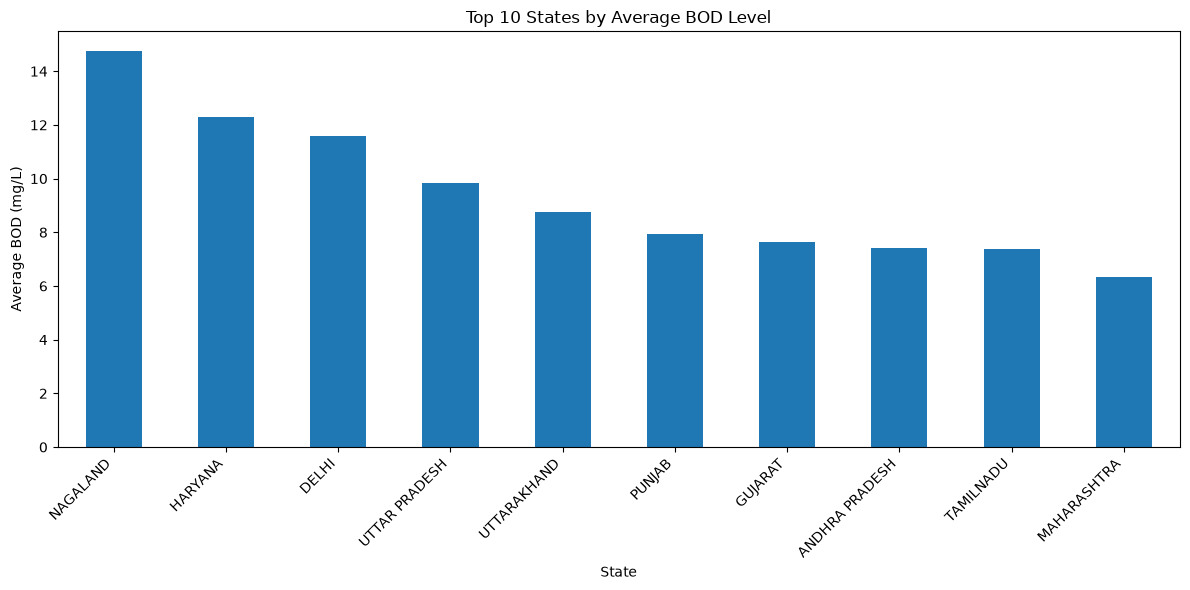

In [31]:
# Identify the mean BOD measurement column
bod_column = [
    column for column in clean_df.columns
    if "B.O.D." in column and ": Mean" in column
][0]

# Calculate average BOD for each state
bod_by_state = clean_df.groupby("STATE")[bod_column].mean()

# Sort states from highest to lowest average BOD
bod_by_state = bod_by_state.sort_values(ascending=False)

# Plot the 10 states with the highest average BOD
plt.figure(figsize=(12, 6))
bod_by_state.head(10).plot(kind="bar")

plt.title("Top 10 States by Average BOD Level")
plt.xlabel("State")
plt.ylabel("Average BOD (mg/L)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Results and Interpretation

The bar chart visualizes the 10 states with the highest average Biochemical Oxygen Demand (BOD) levels.

- The chart shows differences in average BOD levels across states.
- States with higher average BOD values may require closer investigation of their water-quality conditions.
- Higher BOD can indicate greater oxygen demand from organic matter, which may affect dissolved oxygen levels in water.
- Comparing BOD values helps identify regional patterns that may not be apparent from the overall average.

### Conclusion

The visualization provides a clear comparison of average BOD levels across states and helps identify areas for further water-quality investigation. However, the results represent state-level averages and do not establish that every water body in a state is polluted. Further analysis of individual monitoring stations and other water-quality parameters is necessary to identify potential pollution hotspots.

**Limitation:** The analysis uses median-imputed data, which may affect the averages. The chart should be interpreted as an exploratory comparison rather than a definitive assessment of pollution.

# Overall Project Conclusion

This project analyzed water-quality parameters across different states and river categories in India using the *Water Quality in India – 2013* dataset obtained from the Government of India's Data.gov.in portal.

The dataset was combined and cleaned using Python, Pandas, and NumPy. Missing measurements were handled using median imputation, and statistical analysis was performed to calculate average water-quality parameters. The analysis also filtered monitoring locations based on mean BOD levels and grouped measurements by state and water-body type.

Visualizations were created using Matplotlib to compare average BOD levels across states. The results showed variations in water-quality measurements across regions and river categories. These findings help identify patterns and monitoring locations that may require further investigation.

Overall, this project demonstrates how data analysis and visualization can support exploratory water-quality assessment and potential pollution-hotspot screening.

## Challenges and Limitations

- Missing measurements required imputation, which may influence statistical results.
- Water-body categories were inferred from source filenames rather than provided as a dedicated dataset column.
- State-level averages may hide differences between individual monitoring locations.
- The dataset represents measurements from 2013 and may not reflect present-day water quality.
- Further investigation using sampling dates, location details, additional observations, and appropriate water-quality standards is needed to validate potential pollution hotspots.

## Future Scope

Future work could include interactive dashboards, geographical mapping of monitoring stations, analysis of newer water-quality datasets, and multi-parameter hotspot identification using clearly defined criteria.

The project provides a foundation for understanding regional water-quality patterns and demonstrates the value of data analytics in environmental monitoring.